# LuzViva - assistente de IA

O assistente responde dúvidas sobre a manutenção da iluminação pública.

Ao responder, sempre é informado de onde foi tirada a fonte e diz "não consta" quando a informação não está na base.

Como ele responde (código em `api.py`):
1. **Busca (RAG):** acha nos documentos (`base/documentos.jsonl`) os 3 trechos mais parecidos com a pergunta.
2. **Ferramenta:** se a pergunta tiver uma placa (ex.: IP0699800), pega os dados da luminária em `base/luminarias.json`.
3. **Modelo:** o Qwen2.5-1.5B, rodando no próprio PC, lê esses textos e escreve a resposta em JSON.

Neste notebook a gente testa o assistente e mede se ele funciona, com uma prova de 47 perguntas
que já têm a resposta certa (`avaliacao/prova.jsonl`).

In [1]:
import sys, json, unicodedata
sys.path.insert(0, "..")  # para importar o api.py da pasta de cima
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from api import buscar, responder, documentos, LIMIAR

perguntas = [json.loads(l) for l in open("../avaliacao/prova.jsonl", encoding="utf-8")]
print(len(documentos), "trechos na base |", len(perguntas), "perguntas na prova")
# base = resposta nos documentos | fila = resposta nos dados da luminária | nao_consta = fora da base
pd.Series([p["tipo"] for p in perguntas]).value_counts()

W1114 11:37:02.733000 29852 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

47 trechos na base | 47 perguntas na prova


base          30
nao_consta    10
fila           7
Name: count, dtype: int64

## 0. Testando

Troque a pergunta e rode a célula. Para perguntar sobre uma luminária, escreva a placa na pergunta.

In [2]:
pergunta = "Roubaram os fios da minha rua, quanto tempo demora para religar?"
responder(pergunta)["saida"]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

{'resposta': 'O prazo estimado para o religamento das instalações após um furto de fios na rede de iluminação pública é de até 15 dias.',
 'fontes': [{'titulo': 'SP Regula - Perguntas frequentes',
   'trecho': 'Os fios da rede de iluminação pública são do tipo trançados. Nos casos de roubo de fio, as equipes de manutenção comparecem no local e verificam se aconteceu de fato um furto. Constatado o furto de fios, a equipe vai até uma delegacia mais próxima do local para abertura de um Boletim de Ocorrência. Feito o B.O. os fios furtados são repostos e a rede de iluminação restabelecida.'}],
 'recusou': False,
 'confianca': 0.89}

In [2]:
# sobre uma luminária: a placa na pergunta faz o código buscar os dados dela
responder("Qual a prioridade da luminária IP0699800?")["saida"]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

{'resposta': 'Obrigado pela sua consulta. A prioridade da luminária IP0699800 é 90 de 100, pois ela foi classificada como apagada e possui dois relatos de cidadãos. Além disso, a visão computacional apontou falha com confiança 0.95, indicando uma alta probabilidade de falha. Esta luminária está localizada na Avenida Estadual Itapicuru, Campo Limpo, e está a 12,7 metros da luminária vizinha, conforme especificado na documentação. A medição da luz foi realizada entre 18h e 6h, garantindo que os dados sejam precisos.',
 'fontes': [{'titulo': 'LuzViva',
   'trecho': 'Luminária IP0699800, AVENIDA ESTRADA ITAPECIRICA (CAMPO LIMPO). Situação: apagada. Luz funcionando normalmente (está ok)? não, a luminária está apagada. Último lux medido: 0.48 em 11/11 às 20:36. Relatos de cidadãos: 2. Visão computacional apontou falha: sim, com confiança 0.95. Chamado aberto: não. Prioridade: 90 de 100.'}],
 'recusou': False,
 'confianca': 1.0}

In [4]:
# fora da base: o certo é responder "não consta"
responder("Qual o salário de um eletricista da ILUME?")["saida"]

{'resposta': 'Não consta na base do LuzViva.',
 'fontes': [],
 'recusou': True,
 'confianca': 0.0}

## 1. A busca acha o trecho certo?

Para cada pergunta, a busca devolve os 3 trechos mais parecidos, e são esses que vão para o modelo.
- **recall@1:** em quantas perguntas o trecho certo veio em 1º lugar.
- **recall@3:** em quantas ele veio entre os 3. Se não vier, o modelo não tem como acertar.

In [2]:
busca = []
for p in perguntas:
    top = buscar(p["pergunta"], k=3)
    ids = [t["id"] for t, _ in top]
    busca.append({"id": p["id"], "tipo": p["tipo"], "nota": top[0][1], "top3": ids,
                  "acerto1": ids[0] in p["documentos"],
                  "acerto3": any(i in p["documentos"] for i in ids)})
busca = pd.DataFrame(busca)
base = busca[busca.tipo == "base"]  # só as perguntas que têm resposta nos documentos
print(f"recall@1 = {base.acerto1.mean():.3f}   recall@3 = {base.acerto3.mean():.3f}   ({len(base)} perguntas)")
base[~base.acerto3][["id", "nota", "top3"]]  # perguntas em que o trecho certo não veio

recall@1 = 0.700   recall@3 = 0.767   (30 perguntas)


,id,nota,top3
1,P02,0.888968,"[spr-man-06, spr-man-02, lv-02]"
2,P03,0.885422,"[spr-faq-07, spr-amp-02, spr-man-02]"
5,P06,0.857040,"[spr-faq-04, spr-faq-07, spr-faq-02]"
11,P12,0.893263,"[spr-faq-02, spr-faq-08, spr-faq-07]"
13,P14,0.879571,"[spr-faq-07, cmsp-01, aneel-01]"
18,P19,0.873460,"[spr-amp-01, spr-faq-05, spr-faq-09]"
19,P20,0.867289,"[spr-man-01, spr-man-06, spr-amp-03]"


## 2. Quando dizer "não consta"?

Cada trecho recebe uma nota de 0 a 1 de parecença com a pergunta. Se a melhor nota ficar abaixo do
limiar, o assistente responde "não consta". Escolhemos o limiar que melhor separa as perguntas com
resposta das que não constam.

melhor limiar: 0.86 | mantidas: 0.833 | barradas: 0.9


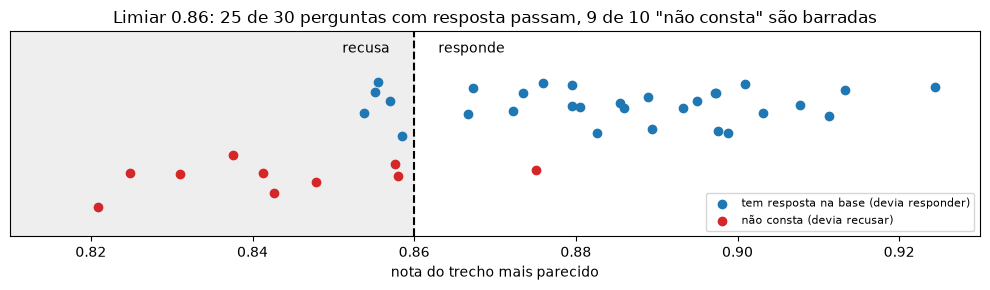

In [3]:
nc = busca[busca.tipo == "nao_consta"]
np.random.seed(0)
limiares = np.round(np.arange(0.78, 0.90, 0.0025), 4)
mantidas = [(base.nota >= l).mean() for l in limiares]  # perguntas com resposta que passam
barradas = [(nc.nota < l).mean() for l in limiares]     # perguntas "não consta" barradas
media = (np.array(mantidas) + np.array(barradas)) / 2
melhor = limiares[media.argmax()]
print("melhor limiar:", melhor, "| mantidas:", round(mantidas[media.argmax()], 3), "| barradas:", round(barradas[media.argmax()], 3))

# cada ponto é uma pergunta; à esquerda da linha o assistente recusa, à direita ele responde
fig, ax = plt.subplots(figsize=(10, 3))
ax.set_xlim(0.81, 0.93)
ax.axvspan(0.81, melhor, color="#eee")
ax.scatter(base.nota, np.random.uniform(0.6, 1.4, len(base)), label="tem resposta na base (devia responder)")
ax.scatter(nc.nota, np.random.uniform(-0.4, 0.4, len(nc)), color="tab:red", label="não consta (devia recusar)")
ax.axvline(melhor, color="k", ls="--")
ax.text(melhor - 0.002, 1.8, "recusa  ", ha="right"); ax.text(melhor + 0.002, 1.8, "  responde")
ax.set_yticks([]); ax.set_ylim(-0.8, 2.1); ax.set_xlabel("nota do trecho mais parecido")
ax.set_title(f"Limiar {melhor}: {(base.nota >= melhor).sum()} de {len(base)} perguntas com resposta passam, "
             f"{(nc.nota < melhor).sum()} de {len(nc)} \"não consta\" são barradas")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("../avaliacao/limiar.png", dpi=120); plt.show()

## 3. Placar: o modelo com e sem os documentos

As mesmas 47 perguntas, com o mesmo modelo, de três jeitos:
- **A:** só o modelo, sem documentos (mostra o quanto ele inventa).
- **B:** RAG, com os 3 trechos da busca.
- **C:** RAG + dados da luminária + JSON garantido (é a do site).

Como cada resposta é corrigida:
- **acerto factual:** a resposta tem as palavras-chave do gabarito (ex.: "15 dias").
- **citou fonte:** citou o documento certo.
- **recusa correta / indevida:** recusou uma pergunta que não consta (certo) ou que tinha resposta (errado).
- **JSON válido:** a resposta veio no formato combinado.
- **acerto total:** factual + fonte certa + JSON (nas "não consta", recusar).

Esta célula leva alguns minutos.

In [7]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", str(s).lower()).encode("ascii", "ignore").decode()

titulo = {d["id"]: d["titulo"] for d in documentos}

def corrigir(p, r, config):
    s = r["saida"]  # o JSON da resposta (None se veio fora do formato)
    resposta = sem_acento(s["resposta"] if s else r["bruto"])
    recusou = bool((s and s["recusou"]) or "nao consta" in resposta)
    fontes = {sem_acento(f.get("titulo", "")) for f in (s["fontes"] if s else []) if isinstance(f, dict)}
    certas = {sem_acento(titulo[i]) for i in p["documentos"]}
    if p["tipo"] == "fila":
        certas.add(sem_acento("Fila de manutenção LuzViva"))
    linha = {"config": config, "id": p["id"], "tipo": p["tipo"], "resposta": s["resposta"] if s else r["bruto"],
             "fontes": sorted(fontes), "json_ok": s is not None, "recusou": recusou, "latencia": r["latencia"],
             "nota_busca": r["nota_busca"], "placa": r["placa"]}
    if p["tipo"] == "nao_consta":
        linha["acerto"] = recusou and s is not None
    else:
        linha["factual"] = not recusou and all(any(sem_acento(a) in resposta for a in g) for g in p["palavras"])
        linha["citou"] = bool(fontes & certas)
        linha["acerto"] = linha["factual"] and linha["citou"] and s is not None
    return linha

responder("aquecimento", "A")  # carrega o modelo antes, para não contar no tempo
res = pd.DataFrame([corrigir(p, responder(p["pergunta"], c), c) for c in "ABC" for p in perguntas])

In [8]:
# tabela do placar (salva em avaliacao/placar.csv)
com_resposta = res[res.tipo != "nao_consta"]
nc = res[res.tipo == "nao_consta"]
placar = pd.DataFrame({
    "acerto total": res.groupby("config").acerto.mean(),
    "acerto factual": com_resposta.groupby("config").factual.mean(),
    "citou fonte": com_resposta.groupby("config").citou.mean(),
    "abstenção correta": nc.groupby("config").recusou.mean(),
    "abstenção indevida": com_resposta.groupby("config").recusou.mean(),
    "JSON válido": res.groupby("config").json_ok.mean(),
    "latência (s)": res.groupby("config").latencia.mean(),
}).round(3)
placar.to_csv("../avaliacao/placar.csv")
placar

,acerto total,acerto factual,citou fonte,abstenção correta,abstenção indevida,JSON válido,latência (s)
config,,,,,,,
A,0.043,0.054054,0.0,0.9,0.730,0.362,4.942
B,0.340,0.540541,0.216216,0.9,0.270,0.702,3.546
C,0.532,0.621622,0.513514,1.0,0.135,1.000,3.084


In [9]:
# acerto por tipo de pergunta (só a C tem os dados das luminárias)
res.pivot_table(index="config", columns="tipo", values="acerto").round(3)

tipo,base,fila,nao_consta
config,,,
A,0.000,0.000,0.2
B,0.233,0.000,0.9
C,0.433,0.286,1.0


## 4. Erros

Tudo que a config C errou. Daqui saíram os 5 erros explicados no README.

In [10]:
pd.set_option("display.max_colwidth", 200)
res[(res.config == "C") & (~res.acerto)][["id", "tipo", "resposta", "fontes", "nota_busca"]]

,id,tipo,resposta,fontes,nota_busca
95,P02,base,A luminária apagada deve ser atendida imediatamente após o protocolo ser aberto.,[],0.889
96,P03,base,Não,[sp regula - perguntas frequentes],0.885
98,P05,base,Não consta na base do LuzViva.,[],0.854
99,P06,base,Não consta na base do LuzViva.,[],0.857
105,P12,base,"A responsabilidade pela manutenção da iluminação pública está definida pelo artigo 23 da Lei nº 4.320/62, que atribui essa função às concessionárias de distribuição de energia elétrica no Brasil.","[aneel, lei no 4.320/62]",0.893
106,P13,base,"Sim, conforme o ANEEL REN 1.000/2021, a distribuidora pode prestar os serviços de manutenção das instalações de iluminação pública mediante celebração de contrato específico, ficando a pessoa jurí...",[aneel ren 1.000/2021],0.908
107,P14,base,O órgão fiscalizador do contrato de concessão da iluminação pública de São Paulo é o Consórcio Ilumina São Paulo.,[[sp regula - perguntas frequentes]],0.880
110,P17,base,Não consta na base do LuzViva.,[],0.859
112,P19,base,"Quando identificar ausência ou deficiência da iluminação pública, deve-se solicitar a instalação de novas lâmpadas ou luminárias.",[sp regula - ampliacao da rede],0.873
113,P20,base,O hospital pode solicitar o serviço através dos canais indicados pela SP Regula. A equipe de manutenção da rede de iluminação pública será responsável por avaliar a situação e realizar os reparos.,"[sp regula - ampliacao da rede, sp regula - manutencao de iluminacao apagada]",0.867


A config A (sem documentos) nas perguntas que não estão na base: quando não recusa, inventa uma resposta.

In [11]:
res[(res.config == "A") & (res.tipo == "nao_consta")][["id", "resposta", "recusou"]]

,id,resposta,recusou
37,N01,Não consta na base do LuzViva.,True
38,N02,Não consta na base do LuzViva.,True
39,N03,Não consta na base do LuzViva.,True
40,N04,Não consta na base do LuzViva.,True
41,N05,Não consta na base do LuzViva.,True
42,N06,Não consta na base do LuzViva.,True
43,N07,A NBR 5101 exige uma iluminância mínima de 2 lux para uma calçada.,False
44,N08,Não consta na base do LuzViva.,True
45,N09,Não consta na base do LuzViva.,True
46,N10,Não consta na base do LuzViva.,True


In [12]:
# das respostas que cada config deu (sem contar as recusas), quantas estavam erradas
deu_resposta = res[~res.recusou]
errou = deu_resposta[(deu_resposta.tipo == "nao_consta") | (deu_resposta.factual == False)]
(errou.groupby("config").size() / deu_resposta.groupby("config").size()).round(2)

config
A    0.82
B    0.29
C    0.28
dtype: float64